# 06 — Flat Cartesian to UNS (number-free), the two hemispheres as one oscillation, and the spirals

**Assistant note.** Written by an AI assistant (Claude) with the author, from `rhp/unsmap.py`, `rhp/chladni.py`, `rhp/coil.py` and the figures `uns_map.svg`, `chladni.svg`, `spirals.svg`.
Labels: ESTABLISHED, OURS, THEORETICAL, CONJECTURE, OPEN; `:CALCULATED` = this code reproduces it. **Nothing here is evidence about RH.**
**Vantage point.** §1 takes any trace (no primes, no ζ): orientation = the complex plane s = σ + it onto the Riemann sphere by the Cayley map and stereographic projection; aperture = the whole plane including ∞.
§2–3 use ξ and ζ at σ ∈ [0,1], t ≤ 50 (or 60), in the chart (latitude π(σ−½), longitude θ(t)) and in the cylindrical chart (angle arg ζ, radius (2/π)arctan|ζ|, height t).

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np, math
from IPython.display import SVG, display
from rhp import unsmap as U, chladni as Ch, coil as K, nodal as N
zeros = np.loadtxt("../data/zeros_1_to_3600.csv")

## 1  Cartesian to UNS without numbers — for GenerationalLineage's artefact detection

line sigma=1/2 -> plane offset from centre, residual: (2.7193665686894618e-18, 1.4454635054260217e-16)
line sigma=0.8 -> plane offset, residual: (0.5144957554275259, 7.221408715408921e-16)
cusp tip speed / median, flat and sphere: (1.9999990728291726e-07, 2.1687199257605295e-07)
edge-on rotation: {'amp_cv': 0.00014105203863490654, 'phase_linear_r2': 0.9999999999894081, 'reversals': 59}
damped oscillator (not a uniform rotation): {'amp_cv': 1.1236224723444856, 'phase_linear_r2': 0.9766260724318393, 'reversals': 19}


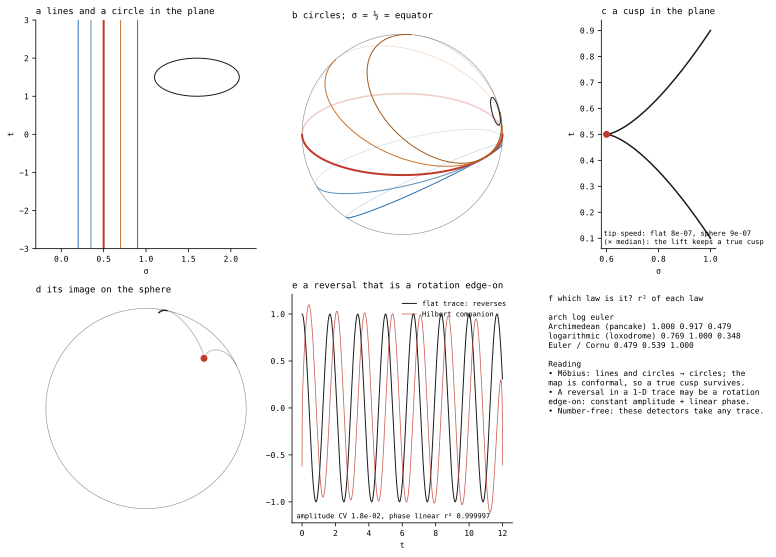

In [2]:
t = np.linspace(-80, 80, 4001)
print("line sigma=1/2 -> plane offset from centre, residual:", U.plane_fit(U.lift(0.5 + 1j*t))[1:])
print("line sigma=0.8 -> plane offset, residual:", U.plane_fit(U.lift(0.8 + 1j*t))[1:])
c = np.linspace(-1, 1, 4001); z = 0.6 + 0.5j + 0.4*(c**2 + 1j*c**3)
print("cusp tip speed / median, flat and sphere:", U.cusp_survives_lift(z, c, 0.0))
tt = np.linspace(0, 60, 6000)
print("edge-on rotation:", U.edge_on_rotation_test(tt, np.cos(2*np.pi*0.5*tt)))
print("damped oscillator (not a uniform rotation):", U.edge_on_rotation_test(tt, np.sin(tt)*np.exp(-tt/10)))
display(SVG("../rhp/atlas_riemann_fermat/uns_map.svg"))

**ESTABLISHED:** Möbius geometry — lines and circles go to circles; the map is conformal; σ = ½ is a great circle, every other vertical line a small circle.
**What a cusp is in UNS.** A genuine cusp stays a cusp (the lift is conformal). A *reversal* of a one-dimensional trace is a different thing: it can be a uniform rotation seen edge-on
(constant analytic-signal amplitude, linear phase), where the Hilbert companion supplies the missing coordinate. This is the test to run before calling a turn-around a cusp.

## 2  The hemispheres as one oscillation, the equator as the nodal line, and 'motion' defined

parity defects (Re even, Im odd): (5.996575208212913e-17, 4.1557064987559634e-16)
flux two ways at sigma=0.7, t=30 (½∂σ|ξ|² vs Im(conj ξ ∂tξ)): (2.6548234625463564e-16, 2.6548234623992205e-16)
flux on the equator: (0.0, -1.2514054992157027e-33)
north points with flux <= 0 in the window: 0
injected delta=0.08 at gamma=25: points with flux <= 0: 3
lobe angle: mean 3.1430 (pi = 3.1416), sd 1.176


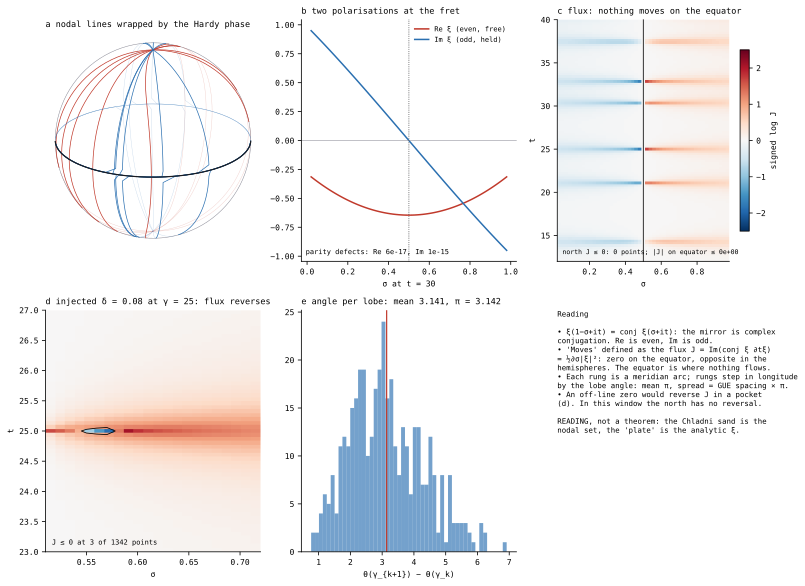

In [3]:
print("parity defects (Re even, Im odd):", Ch.parity_defect([0.05, 0.3], [14.0, 30.0]))
print("flux two ways at sigma=0.7, t=30 (½∂σ|ξ|² vs Im(conj ξ ∂tξ)):", Ch.flux_two_ways(0.7, 30.0))
print("flux on the equator:", Ch.flux_two_ways(0.5, 30.0))
sig = np.linspace(0.3, 0.8, 11); t_ = np.linspace(13, 27, 36)
print("north points with flux <= 0 in the window:", Ch.north_violations(Ch.rel_flux_grid(sig, t_), sig))
f = Ch.with_offline_quadruple(0.08, 25.0)
s2 = np.linspace(0.5, 0.72, 23)[1:]; t2 = np.linspace(24, 26, 41)
print("injected delta=0.08 at gamma=25: points with flux <= 0:", int((Ch.rel_flux_grid(s2, t2, f) <= 0).sum()))
la = Ch.lobe_angles(zeros[:600]); print("lobe angle: mean %.4f (pi = %.4f), sd %.3f" % (la.mean(), math.pi, la.std()))
display(SVG("../rhp/atlas_riemann_fermat/chladni.svg"))

ξ(1−σ+it) = conj ξ(σ+it): the mirror at fixed height is complex conjugation, so Re ξ is even (a free end) and Im ξ is odd (a held point): two polarisations with different boundary conditions at the equator.
**'Moves', defined here:** the flux J = Im(conj ξ ∂ξ/∂t) = ½ ∂σ|ξ|² (Cauchy–Riemann). It is exactly zero on the equator and opposite in the two hemispheres; the equator is where nothing flows.
A negative-flux pocket is the footprint of an off-line zero (tested by injection only). The lobe angle between consecutive zeros averages π with the spread of the GUE zero spacing.

## 3  The spirals: pancake coil, Hardy angle, partial sums, and the conical helices of the explicit formula

taps (turns -> zero index, height): {'T1': (2, 21.022039638772), 'T3': (6, 37.586178158826), 'T5': (10, 49.773832477672), 'T_full': (34, 111.02953554317)}
radius law, first 34 zeros: {'index_vs_angle': 0.9996058551070472, 'height_vs_angle': 0.989901433589478}
radius law, first 300 zeros: {'index_vs_angle': 0.9999923980394946, 'height_vs_angle': 0.9944132856407581}
height-wound pitch 4π/ln(t/2π) at t = 20, 200, 2000: [10.85314514  3.63143691  2.18051627]
partial-sum spiral about zeta(s), sigma=0.5: measured, predicted d ln r/dφ: (-0.004998465403518233, -0.005)
partial-sum spiral about zeta(s), sigma=0.8: measured, predicted d ln r/dφ: (-0.0019984654358356445, -0.0019999999999999996)
partial-sum spiral about zeta(s), sigma=1.0: measured, predicted d ln r/dφ: (1.5345579615250992e-06, -0.0)
partial-sum spiral about zeta(s), sigma=1.5: measured, predicted d ln r/dφ: (0.005001534596149386, 0.005)
min |zeta| from the t-axis, t in [10,60]: {0.5: 0.0019705264938189187, 0.6: 0.07626634334295831,

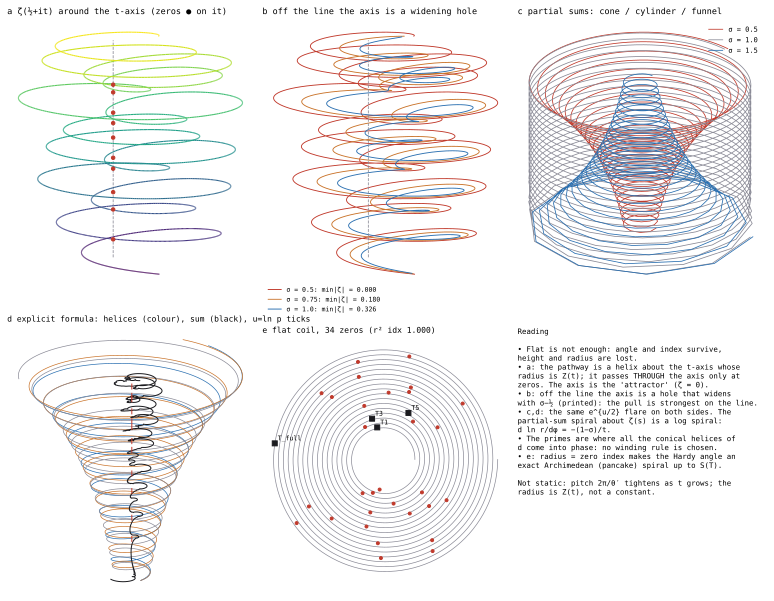

In [4]:
print("taps (turns -> zero index, height):", K.tap_zeros(zeros))
print("radius law, first 34 zeros:", K.radius_law(zeros[:34])); print("radius law, first 300 zeros:", K.radius_law(zeros[:300]))
print("height-wound pitch 4π/ln(t/2π) at t = 20, 200, 2000:", K.hardy_pitch_t([20, 200, 2000]))
for sg in (0.5, 0.8, 1.0, 1.5): print("partial-sum spiral about zeta(s), sigma=%.1f: measured, predicted d ln r/dφ:" % sg, K.tail_log_slope(100, 800, 8000, sg))
print("min |zeta| from the t-axis, t in [10,60]:", K.axis_distance(np.linspace(10, 60, 4000)))
display(SVG("../rhp/atlas_riemann_fermat/spirals.svg"))

**Findings.** (1) A pancake coil with one turn per two zeros, radius = zero index, makes the Hardy angle an Archimedean spiral to r² > 0.9999 (the departure is S(T)); winding on the height t instead gives a pitch 4π/ln(t/2π) that tightens.
(2) The partial sums Σ n^{−s} spiral about the value ζ(s) logarithmically, d ln r/dφ = −(1−σ)/t, verified at four latitudes: a cone at σ < 1 (the line σ = ½ flares as e^{u/2}), a cylinder at σ = 1, a funnel at σ > 1.
(3) The zero tones of the explicit formula are conical helices with the same e^{u/2} flare; the primes are where they come into phase. (4) The pathway ζ(½+it) threads the t-axis (ζ = 0) only at zeros; off the line the axis is a hole whose radius grows with σ − ½.
**Honest limit.** None of these shows an *operator that identifies the primes*; they show the geometry the explicit formula and the Euler product force, with no winding rule chosen.

## 4  Anomaly log (Chase Every Anomaly)
| # | Anomaly | Verdict |
|---|---|---|
| 1 | My first sign for the partial-sum spiral was wrong (I predicted inward convergence on the critical line) | MATHS (mine): at σ = ½ the tail grows as N^{1/2}; corrected, verified at 4 latitudes |
| 2 | A test constant for the sphere's geodesic curvature was wrong (0.75 instead of cot a = 4/3) | CODE (test): fixed; the formula was right |
| 3 | 'Double helix' for the nodal rungs was too strong | METHOD: each rung is a meridian arc; wording corrected |
| 4 | Flux J is ~1e-10 and the first map was blank | METHOD: use the scale-free ∂σ ln|ξ| (same sign) |